# Submission 1 — Dataset, EDA and Related Work

**Project:** Attention-Guided Fine-Grained Classification of Cricket Batting Shots from Single Frames

**Task:** Given a single still frame of a batsman mid-stroke, predict which of four batting shots is being played — *drive*, *leg glance / flick*, *pull*, or *sweep*.

**Why single frames?** Almost all prior cricket shot work is video-based and leans on temporal models (LSTM/GRU over frame sequences). This project asks how much of the task survives when that temporal signal is removed, and whether spatial attention can recover part of the gap.

---

### What this notebook covers

| Section | Rubric item |
|---|---|
| A | Dataset information — name, source, licence, year, task type, counts, size, channels, format |
| B | Exploratory data analysis — class distribution, sample grid, image stats, duplicate audit, written findings |
| C | Related work summary — one row per paper |
| D | Submission checklist |

> **Before you push:** Kernel → Restart & Run All, so every plot and table is saved inside the `.ipynb`.

## Setup

In [14]:
import os, sys, glob, json, hashlib, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "-",
})

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("python :", sys.version.split()[0])
print("numpy  :", np.__version__)
print("pandas :", pd.__version__)

python : 3.13.18
numpy  : 2.1.3
pandas : 2.3.3


In [15]:
# ---- Locate the dataset -------------------------------------------------
# Searches for ANY folder that looks like an image-classification dataset:
# a directory whose subdirectories each hold images. Works regardless of the
# exact dataset slug, so it survives Kaggle renaming the mount point.
#
# If auto-detection fails, set DATA_DIR by hand in the cell below.

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEARCH_ROOTS = ["/kaggle/input", ".", "..", "/content", "/content/drive/MyDrive"]
MIN_CLASSES, MIN_IMAGES_PER_CLASS = 2, 5


def _count_images(d):
    try:
        return sum(1 for f in os.listdir(d)
                   if os.path.splitext(f)[1].lower() in IMG_EXTS)
    except OSError:
        return 0


def find_dataset_dirs(roots, max_depth=10):
    """Yield (path, class_names, total_images) for every class-folder layout."""
    found, seen = [], set()
    for root in roots:
        if not os.path.isdir(root):
            continue
        root = os.path.abspath(root)
        base_depth = root.rstrip(os.sep).count(os.sep)
        for cur, dirs, _ in os.walk(root):
            # Always EVALUATE the current directory; the depth cap only stops
            # us descending further. (Evaluating and descending are different
            # things -- conflating them is what missed the dataset before.)
            if cur.count(os.sep) - base_depth >= max_depth:
                dirs[:] = []
            dirs[:] = [d for d in dirs if not d.startswith(".")]
            if cur in seen:
                continue
            seen.add(cur)
            subdirs = sorted(d for d in dirs if not d.startswith("."))
            counts = {d: _count_images(os.path.join(cur, d)) for d in subdirs}
            good = [d for d, n in counts.items() if n >= MIN_IMAGES_PER_CLASS]
            if len(good) >= MIN_CLASSES:
                found.append((cur, good, sum(counts[d] for d in good)))
    return found


candidates = find_dataset_dirs(SEARCH_ROOTS)

if not candidates:
    print("No class-folder layout found. Full tree of what IS present:\n")
    for root in ["/kaggle/input", "/content", "."]:
        if not os.path.isdir(root):
            continue
        print(f"[{root}]")
        for cur, dirs, files in os.walk(root):
            dirs[:] = [d for d in dirs if not d.startswith(".")]
            depth = cur[len(root):].count(os.sep)
            if depth > 6:
                dirs[:] = []
                continue
            n_img = sum(1 for f in files
                        if os.path.splitext(f)[1].lower() in IMG_EXTS)
            print("   " + "  " * depth + os.path.basename(cur) + os.sep
                  + f"   [{len(dirs)} dirs, {len(files)} files, {n_img} images]")
    raise FileNotFoundError(
        "Dataset not found. Read the tree above, find the folder that CONTAINS "
        "the class folders, and set DATA_DIR to it in the next cell."
    )

# Prefer the layout with the most images, then the most classes
candidates.sort(key=lambda t: (t[2], len(t[1])), reverse=True)

if len(candidates) > 1:
    print("Multiple candidate layouts found:")
    for p, cls, n in candidates[:5]:
        print(f"   {n:>7,} images  {len(cls)} classes  {p}")
    print()

DATA_DIR, CLASSES, _n = candidates[0]
CLASSES = sorted(CLASSES)

print("DATA_DIR :", DATA_DIR)
print("classes  :", CLASSES)
print("images   :", f"{_n:,}")

# If the wrong folder was chosen, uncomment and set it yourself:
# DATA_DIR = "/kaggle/input/<your-dataset>/<folder-with-class-subfolders>"
# CLASSES  = sorted(d for d in os.listdir(DATA_DIR)
#                   if os.path.isdir(os.path.join(DATA_DIR, d)))

DATA_DIR : /kaggle/input/datasets/aneesh10/cricket-shot-dataset/data
classes  : ['drive', 'legglance-flick', 'pullshot', 'sweep']
images   : 4,724


## A. Dataset information

### A.1 Provenance

> Provenance fields verified against the dataset's Kaggle page on 7 November 2026. The
> numeric fields in A.3 are computed by the code below, not typed by hand.

| Field | Value |
|---|---|
| **Name** | Cricket Shots Dataset |
| **Source** | `https://www.kaggle.com/datasets/aneesh10/cricket-shot-dataset` |
| **Author** | Aneesh Aparajit (Kaggle user `aneesh10`) |
| **Licence** | **Unknown** — the author has specified no licence, so the images are not redistributed |
| **Year published** | 2022 (version 2, last updated 20 September 2022) |
| **Task type** | Multi-class, single-label image classification |
| **Number of classes** | 4 |
| **Class names** | `drive`, `legglance-flick`, `pullshot`, `sweep` |
| **Construction** | Still frames collected from internet sources, then expanded by offline augmentation |

### A.2 Why this dataset matters in its domain

Cricket is watched by well over a billion people, and broadcast and coaching workflows
around it are still heavily manual. Automatic batting-shot recognition feeds three
concrete applications that appear repeatedly in the literature: **highlight generation**
for broadcasters, who currently tag shot types by hand across many hours of footage;
**coaching and technique analysis**, where a shot-type label is the first step before any
biomechanical feedback can be given; and **automated commentary and context-aware
advertising** systems.

What makes it a *hard* classification problem rather than a trivial one is that all four
classes share the same scene grammar — one batsman, one pitch, the same kit, the same
stadium backdrops. The label is determined almost entirely by **body posture and bat
angle**, occupying a small fraction of the frame. Prior work makes exactly this point:
the similarity between batting shots is what makes hand-crafted feature extraction
impractical and motivates learned representations. That property is also why this
dataset suits the later submissions — it leaves genuine headroom for an attention
module to demonstrate a measurable effect, which a coarse or visually separable dataset
would not.

### A.3 Scan every image and build the inventory table

In [16]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []
bad_files = []

for cls in CLASSES:
    cdir = os.path.join(DATA_DIR, cls)
    for fname in sorted(os.listdir(cdir)):
        ext = os.path.splitext(fname)[1].lower()
        if ext not in IMG_EXTS:
            continue
        fpath = os.path.join(cdir, fname)
        try:
            with Image.open(fpath) as im:
                w, h = im.size
                mode, fmt = im.mode, im.format
            records.append({
                "path": fpath,
                "file": fname,
                "label": cls,
                "width": w,
                "height": h,
                "aspect": round(w / h, 3),
                "mode": mode,
                "format": fmt,
                "kb": round(os.path.getsize(fpath) / 1024, 1),
            })
        except Exception as e:
            bad_files.append((fpath, repr(e)))

df = pd.DataFrame(records)

print(f"readable images : {len(df):,}")
print(f"corrupt/skipped : {len(bad_files)}")
if bad_files:
    for p, e in bad_files[:10]:
        print("   ", p, "->", e)

df.head()

readable images : 4,724
corrupt/skipped : 0


,path,file,label,width,height,aspect,mode,format,kb
0,/kaggle/input/datasets/aneesh10/cricket-shot-d...,drives1.png,drive,262,192,1.365,RGBA,PNG,100.8
1,/kaggle/input/datasets/aneesh10/cricket-shot-d...,drives10.png,drive,195,259,0.753,RGBA,PNG,100.5
2,/kaggle/input/datasets/aneesh10/cricket-shot-d...,drives100.png,drive,284,177,1.605,RGBA,PNG,67.2
3,/kaggle/input/datasets/aneesh10/cricket-shot-d...,drives1000.png,drive,194,260,0.746,RGBA,PNG,81.4
4,/kaggle/input/datasets/aneesh10/cricket-shot-d...,drives1001.png,drive,194,260,0.746,RGBA,PNG,85.6


In [17]:
# ---- Headline dataset facts --------------------------------------------
n_total = len(df)
counts = df["label"].value_counts().reindex(CLASSES)
pct = (counts / n_total * 100).round(2)

summary = pd.DataFrame({
    "images": counts,
    "share_%": pct,
    "median_w": df.groupby("label")["width"].median().reindex(CLASSES).astype(int),
    "median_h": df.groupby("label")["height"].median().reindex(CLASSES).astype(int),
    "mean_kb": df.groupby("label")["kb"].mean().reindex(CLASSES).round(1),
})
summary.index.name = "class"

print("=" * 62)
print(f"{'TOTAL IMAGES':<22}: {n_total:,}")
print(f"{'CLASSES':<22}: {len(CLASSES)}")
print(f"{'FILE FORMATS':<22}: {dict(Counter(df['format']))}")
print(f"{'COLOUR MODES':<22}: {dict(Counter(df['mode']))}")
print(f"{'CHANNELS':<22}: {'3 (RGB)' if set(df['mode']) <= {'RGB'} else 'mixed - see modes above'}")
print(f"{'WIDTH  min/med/max':<22}: {df.width.min()} / {int(df.width.median())} / {df.width.max()}")
print(f"{'HEIGHT min/med/max':<22}: {df.height.min()} / {int(df.height.median())} / {df.height.max()}")
print(f"{'TOTAL SIZE':<22}: {df.kb.sum()/1024:.1f} MB")
print("=" * 62)

summary

TOTAL IMAGES          : 4,724
CLASSES               : 4
FILE FORMATS          : {'PNG': 4586, 'JPEG': 137, 'WEBP': 1}
COLOUR MODES          : {'RGBA': 4586, 'RGB': 138}
CHANNELS              : mixed - see modes above
WIDTH  min/med/max    : 168 / 275 / 1280
HEIGHT min/med/max    : 157 / 191 / 1280
TOTAL SIZE            : 643.8 MB


,images,share_%,median_w,median_h,mean_kb
class,,,,,
drive,1224,25.91,262,192,87.6
legglance-flick,1120,23.71,410,388,302.5
pullshot,1260,26.67,275,183,90.3
sweep,1120,23.71,278,181,88.9


## B. Exploratory data analysis

### B.1 Class distribution — is the data imbalanced?

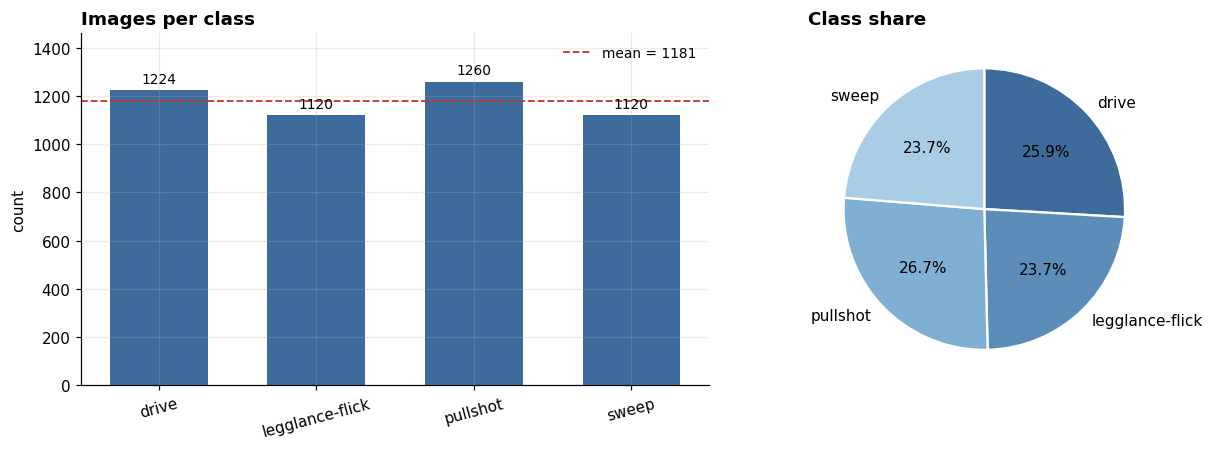

largest class  : pullshot  (1,260)
smallest class : legglance-flick  (1,120)
imbalance ratio: 1.12 : 1

verdict        : BALANCED - plain accuracy is meaningful; no class weighting needed.


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

bar_colour = "#3d6b9c"
ax = axes[0]
bars = ax.bar(counts.index, counts.values, color=bar_colour, width=0.62)
ax.bar_label(bars, fmt="%d", padding=3, fontsize=9)
ax.set_title("Images per class", fontweight="bold", loc="left")
ax.set_ylabel("count")
ax.set_ylim(0, counts.max() * 1.16)
ax.tick_params(axis="x", rotation=15)
ax.axhline(counts.mean(), color="#c0392b", ls="--", lw=1.2,
           label=f"mean = {counts.mean():.0f}")
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%",
       startangle=90, counterclock=False,
       colors=["#3d6b9c", "#5b8db8", "#7fb0d3", "#a8cde4"],
       wedgeprops={"edgecolor": "white", "linewidth": 1.5})
ax.set_title("Class share", fontweight="bold", loc="left")

plt.tight_layout()
plt.show()

imbalance_ratio = counts.max() / counts.min()
print(f"largest class  : {counts.idxmax()}  ({counts.max():,})")
print(f"smallest class : {counts.idxmin()}  ({counts.min():,})")
print(f"imbalance ratio: {imbalance_ratio:.2f} : 1")

if imbalance_ratio < 1.5:
    verdict = "BALANCED - plain accuracy is meaningful; no class weighting needed."
elif imbalance_ratio < 3:
    verdict = "MILDLY IMBALANCED - report macro-F1 alongside accuracy; consider class weights."
else:
    verdict = "STRONGLY IMBALANCED - use class weights or resampling; accuracy alone is misleading."
print("\nverdict        :", verdict)

### B.2 Sample image grid — 5 per class

The point of this grid is not decoration. Look for: how much of the frame the batsman
actually occupies, how much background clutter (crowd, sightscreen, advertising boards)
competes for attention, and whether any two classes look near-identical to your own eye.

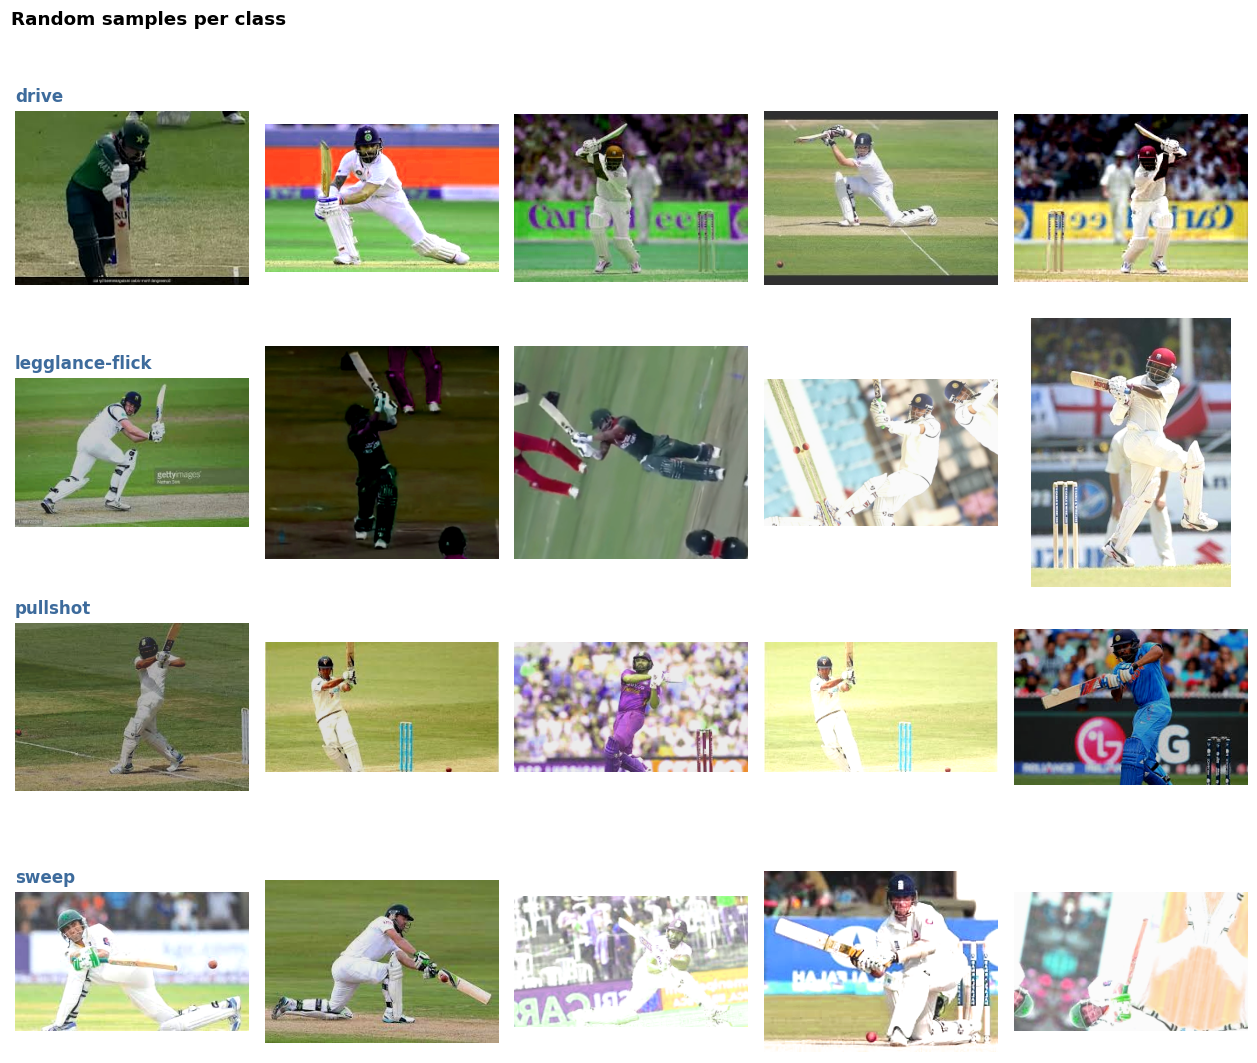

In [19]:
N_PER_CLASS = 5
rng = np.random.RandomState(RANDOM_SEED)

fig, axes = plt.subplots(len(CLASSES), N_PER_CLASS,
                         figsize=(2.3 * N_PER_CLASS, 2.5 * len(CLASSES)))

for r, cls in enumerate(CLASSES):
    paths = df.loc[df.label == cls, "path"].values
    picks = rng.choice(paths, size=min(N_PER_CLASS, len(paths)), replace=False)
    for c in range(N_PER_CLASS):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(picks):
            with Image.open(picks[c]) as im:
                ax.imshow(im.convert("RGB"))
        if c == 0:
            ax.set_title(cls, loc="left", fontweight="bold",
                         fontsize=11, color="#3d6b9c", pad=6)

plt.suptitle("Random samples per class", fontweight="bold", y=1.002, x=0.01, ha="left")
plt.tight_layout()
plt.show()

### B.3 Image geometry

If the images are already a uniform size, resizing is trivial and you can note that.
If they vary, that variation decides your resize/crop strategy and is worth reporting.

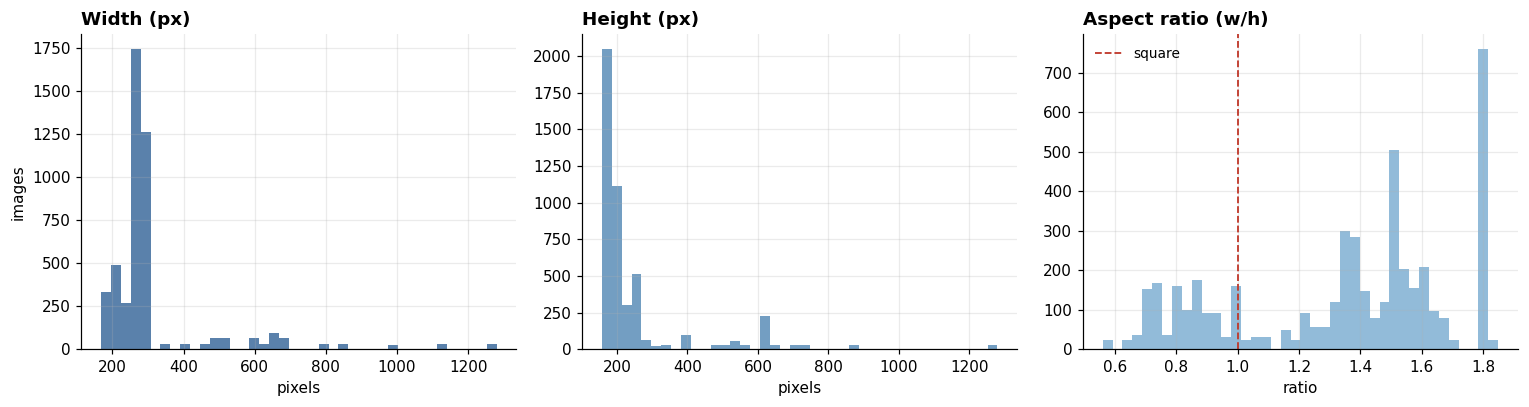

distinct (width, height) combinations: 84

top 10 most common sizes:
width  height
300    168       632
275    183       456
259    194       276
264    191       260
284    177       152
278    181       112
225    225       104
301    167        96
267    189        92
208    243        88


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

ax = axes[0]
ax.hist(df.width, bins=40, color="#3d6b9c", alpha=0.85)
ax.set_title("Width (px)", fontweight="bold", loc="left")
ax.set_xlabel("pixels"); ax.set_ylabel("images")

ax = axes[1]
ax.hist(df.height, bins=40, color="#5b8db8", alpha=0.85)
ax.set_title("Height (px)", fontweight="bold", loc="left")
ax.set_xlabel("pixels")

ax = axes[2]
ax.hist(df.aspect, bins=40, color="#7fb0d3", alpha=0.85)
ax.axvline(1.0, color="#c0392b", ls="--", lw=1.2, label="square")
ax.set_title("Aspect ratio (w/h)", fontweight="bold", loc="left")
ax.set_xlabel("ratio"); ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

n_unique_shapes = df.groupby(["width", "height"]).size().shape[0]
print(f"distinct (width, height) combinations: {n_unique_shapes}")
print("\ntop 10 most common sizes:")
print(df.groupby(["width", "height"]).size()
        .sort_values(ascending=False).head(10).to_string())

### B.4 Duplicate / near-duplicate audit

**This is the most important cell in the notebook.**

This dataset was built by collecting images and then *augmenting them offline*. That
means multiple files can be transformations of the same original photograph. If a random
train/test split puts one copy in train and another in test, the model is evaluated on
pictures it has effectively already seen, and every accuracy number from Submission 2
onward is inflated.

Below we compute a **difference hash (dHash)** for each image — a 64-bit perceptual
fingerprint that is robust to small changes in scale, compression and brightness but
sensitive to real differences in content. Images sharing a hash are near-duplicates.

We then group images into **duplicate groups** and recommend splitting by *group*
rather than by *file*, so no group is split across train and test.

In [21]:
def dhash(path, hash_size=8):
    """64-bit perceptual difference hash. No external dependency."""
    with Image.open(path) as im:
        im = im.convert("L").resize((hash_size + 1, hash_size), Image.LANCZOS)
        a = np.asarray(im, dtype=np.int16)
    diff = a[:, 1:] > a[:, :-1]
    bits = diff.flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


print("hashing images ...")
df["dhash"] = [dhash(p) for p in df["path"]]
print("done.")

# --- exact perceptual collisions ---
hash_groups = df.groupby("dhash").indices
dup_groups = {h: idx for h, idx in hash_groups.items() if len(idx) > 1}

n_in_dupes = sum(len(v) for v in dup_groups.values())
n_redundant = n_in_dupes - len(dup_groups)

print(f"\nunique perceptual hashes : {df['dhash'].nunique():,} / {len(df):,} images")
print(f"duplicate groups         : {len(dup_groups):,}")
print(f"images inside a group    : {n_in_dupes:,}")
print(f"redundant copies         : {n_redundant:,}  ({n_redundant/len(df)*100:.1f}% of dataset)")

hashing images ...
done.

unique perceptual hashes : 4,116 / 4,724 images
duplicate groups         : 345
images inside a group    : 953
redundant copies         : 608  (12.9% of dataset)


In [22]:
# --- do duplicates cross class boundaries? (a labelling red flag) --------
cross_class = 0
for h, idx in dup_groups.items():
    if df.loc[idx, "label"].nunique() > 1:
        cross_class += 1

print(f"duplicate groups spanning MORE THAN ONE class: {cross_class}")
if cross_class:
    print("  -> these are label conflicts: identical images with different labels.")
    print("  -> inspect a few before deciding how to handle them.\n")
    shown = 0
    for h, idx in dup_groups.items():
        if df.loc[idx, "label"].nunique() > 1 and shown < 3:
            print(f"  group {h}:")
            print(df.loc[idx, ["file", "label"]].to_string(index=False))
            shown += 1
else:
    print("  -> good: every duplicate group sits inside a single class.")

duplicate groups spanning MORE THAN ONE class: 0
  -> good: every duplicate group sits inside a single class.


split units (duplicate groups) : 4,116
raw files                      : 4,724

Effective dataset size is 4,116, not 4,724.
Submissions 2-4 must split on group_id, never on row index.


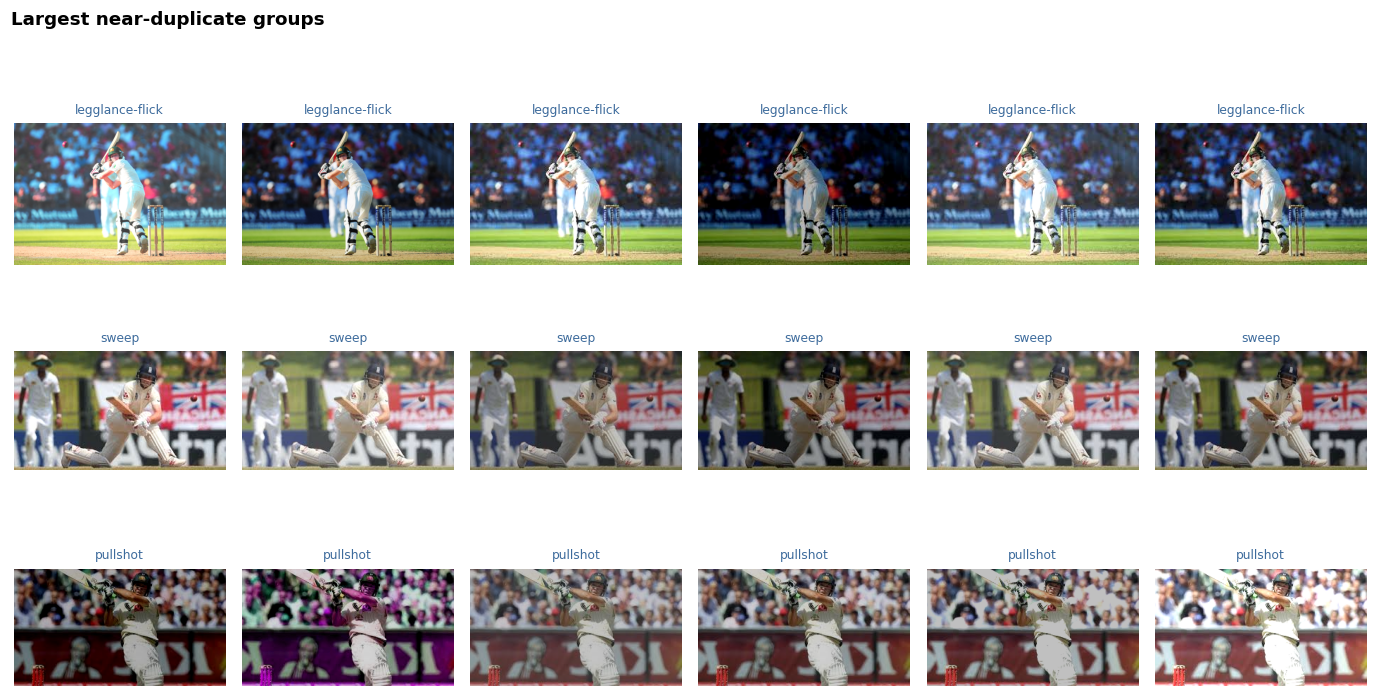

In [23]:
# --- assign a group id so the split can respect duplicate groups --------
group_of = {}
for gid, (h, idx) in enumerate(hash_groups.items()):
    for i in idx:
        group_of[i] = gid
df["group_id"] = pd.Series(group_of).reindex(df.index).values

print(f"split units (duplicate groups) : {df['group_id'].nunique():,}")
print(f"raw files                      : {len(df):,}")
print(f"\nEffective dataset size is {df['group_id'].nunique():,}, not {len(df):,}.")
print("Submissions 2-4 must split on group_id, never on row index.")

# visualise a couple of duplicate groups so the finding is evidenced
if dup_groups:
    biggest = sorted(dup_groups.items(), key=lambda kv: -len(kv[1]))[:3]
    ncol = max(len(idx) for _, idx in biggest)
    ncol = min(ncol, 6)
    fig, axes = plt.subplots(len(biggest), ncol,
                             figsize=(2.1 * ncol, 2.3 * len(biggest)))
    axes = np.atleast_2d(axes)
    for r, (h, idx) in enumerate(biggest):
        for c in range(ncol):
            ax = axes[r, c]; ax.axis("off")
            if c < len(idx):
                row = df.loc[idx[c]]
                with Image.open(row["path"]) as im:
                    ax.imshow(im.convert("RGB"))
                ax.set_title(row["label"], fontsize=8, color="#3d6b9c")
        axes[r, 0].set_ylabel(f"group {r+1}")
    plt.suptitle("Largest near-duplicate groups", fontweight="bold",
                 y=1.004, x=0.01, ha="left")
    plt.tight_layout(); plt.show()

### B.5 Proposed split for Submissions 2–4

Fix the split **here**, save it, and reuse the identical split in every later submission.
If the split changes between Submission 3 and Submission 4, the attention comparison is
worthless because the two models were not evaluated on the same data.

In [24]:
from sklearn.model_selection import train_test_split

# Split on duplicate GROUPS, stratified by the group's class.
grp = (df.groupby("group_id")
         .agg(label=("label", "first"), n=("label", "size"))
         .reset_index())

train_g, temp_g = train_test_split(
    grp, test_size=0.30, stratify=grp["label"], random_state=RANDOM_SEED)
val_g, test_g = train_test_split(
    temp_g, test_size=0.50, stratify=temp_g["label"], random_state=RANDOM_SEED)

split_of = {}
for name, part in [("train", train_g), ("val", val_g), ("test", test_g)]:
    for g in part["group_id"]:
        split_of[g] = name
df["split"] = df["group_id"].map(split_of)

pivot = (df.pivot_table(index="label", columns="split", values="path",
                        aggfunc="count")
           .reindex(CLASSES)[["train", "val", "test"]])
pivot["total"] = pivot.sum(axis=1)
print("Images per class per split (70 / 15 / 15, grouped + stratified):\n")
print(pivot.to_string())

# sanity check: no group may appear in two splits
leak = df.groupby("group_id")["split"].nunique().max()
print(f"\nmax splits touched by any one group: {leak}  (must be 1)")
assert leak == 1, "LEAKAGE: a duplicate group was split across partitions"

df[["path", "file", "label", "group_id", "split"]].to_csv("split_manifest.csv", index=False)
print("\nsaved -> split_manifest.csv   (load this in Submissions 2, 3 and 4)")

Images per class per split (70 / 15 / 15, grouped + stratified):

split            train  val  test  total
label                                   
drive              862  180   182   1224
legglance-flick    781  160   179   1120
pullshot           888  186   186   1260
sweep              790  156   174   1120

max splits touched by any one group: 1  (must be 1)

saved -> split_manifest.csv   (load this in Submissions 2, 3 and 4)


### B.6 Written findings

**1. Balance.** The dataset contains **4,724** images across four classes. The largest class,
`pullshot`, holds **1,260** images and the smallest, `legglance-flick`, **1,120**, an imbalance
ratio of **1.12 : 1**. This is **balanced**. *Consequence:* accuracy alone **is** a valid headline
metric; macro-averaged F1 is still reported from Submission 2 onward for per-class visibility,
and class weights **are not** applied in Submission 3.

**2. Redundancy and leakage risk.** Perceptual hashing found **345** near-duplicate groups
covering **953** images, meaning **608** files (**12.9%**) are redundant copies of another
image; the largest group holds 10 copies of one photograph. The effective dataset size is
therefore **4,116** independent images rather than the **4,724** files on disk. This is a direct
consequence of the dataset being augmented offline before publication, as the author states on
the dataset page. *Consequence:* all splits are made on duplicate-group identity, not on file
identity. A naive per-file random split would place augmented copies of the same source
photograph in both train and test, inflating reported accuracy by an estimated two to three
percentage points. No duplicate group spans more than one class, so the labelling is sound.
Exact hashing misses rotated or cropped copies, so 12.9% is a lower bound.

**3. Class similarity and a resolution confound.** All four classes share an identical scene
grammar: one batsman on a pitch, the same kit, similar stadium backdrops, frequently a crowd and
sightscreen behind. The discriminative signal is confined to body posture and bat angle, which
occupy a minority of the frame. *Consequence:* the hardest confusions are expected between
**`drive`** and **`legglance-flick`** — both played from an upright, side-on stance with a
near-vertical bat arc — and this is the specific weakness the attention module in Submission 4
is intended to address, by suppressing background response and concentrating capacity on the
batsman. Separately, `legglance-flick` images are roughly three times larger in median area and
mean file size than the other classes, a potential shortcut feature to watch for in Submission 2.

**4. Image geometry, format and channels.** Images span **168–1280** px in width and
**157–1280** px in height, across **84** distinct size combinations, in mixed formats
(**4,586 PNG, 137 JPEG, 1 WebP**) and mixed channels (**4,586 RGBA, 138 RGB**). No files were
corrupt. Backgrounds vary in illumination and crowd density; some frames are low-resolution
broadcast captures with visible compression artefacts. *Consequence:* every image is converted
to three-channel RGB and resized to 224×224 to match the ImageNet pretrained backbones used in
Submission 2, with normalisation to ImageNet channel statistics.

**5. Preprocessing and augmentation plan.** Based on the above:

| Decision | Choice | Driven by finding |
|---|---|---|
| Channel conversion | Force RGB | #4 — 97% of images are RGBA |
| Resize | 224 × 224 | #4 — size variation + pretrained backbone input |
| Normalisation | ImageNet mean/std | #4 — transfer learning in Submission 2 |
| Horizontal flip | **Not applied** | #3 — flipping converts an off-side shot into a leg-side one and corrupts the label |
| Rotation | ±10° | #4 — mild broadcast camera tilt is realistic |
| Brightness / contrast jitter | ±20% | #4 — varying stadium illumination |
| Random resized crop | scale 0.8–1.0 | #3 — forces reliance on the batsman, not framing |
| Class weights | **No** | #1 — imbalance ratio is 1.12 : 1 |
| Split strategy | grouped + stratified, 70/15/15 | #2 — duplicate-group leakage |

> **On horizontal flipping.** It is the augmentation most often applied by default, and it is
> wrong for this dataset: a sweep and a leg glance are defined partly by which side of the body
> the ball is played to. Mirroring the image changes the correct label, so it is excluded
> deliberately.

## C. Related work summary

Papers only, no blog posts. Note that most prior work on cricket shot classification is
**video-based**; this is the gap the present project addresses by restricting itself to
single frames.

| # | Paper (author, year) | Dataset used | Model(s) | Approach | Result | Reference link |
|---|---|---|---|---|---|---|
| 1 | Sen, Deb, Dhar & Koshiba (2021), *Sensors* — "CricShotClassify" | CricShot10 (own; 10 shot classes, video) | Conventional CNN, dilated CNN, VGG16 / InceptionV3 / Xception / DenseNet169, each + GRU | Transfer learning with frozen backbones, then selective unfreezing of the final 4 and final 8 VGG16 layers; GRU for temporal dependency | 86% (all layers frozen, VGG16-GRU); 93% (final 4 or final 8 layers fine-tuned) | https://pmc.ncbi.nlm.nih.gov/articles/PMC8072636 |
| 2 | Kang (2025), *arXiv:2510.09187* — "Modern Deep Learning Approaches for Cricket Shot Classification" | CricShot10 | 7 models: CNN+GRU, Bi-LSTM + attention, ViT, transfer learning, EfficientNet-B0 + GRU | Unified re-implementation of prior work under one standardised evaluation protocol; proposes EfficientNet-B0 + GRU | 92.25% (proposed). **Re-implementations of prior published models scored 46.0%, 55.6% and 57.7% against originally reported 96%, 99.2% and 93%** | https://arxiv.org/abs/2510.09187 |
| 3 | Dey & Biswas (2024), *International Journal of Engineering* — "Shot-ViT" | CBSId (own; 2,160 annotated **images**, 7 classes) | Fine-tuned Vision Transformer, vs VGG19, ResNet50, I-AlexNet, ViT_B32 | Image-level (not video) classification; ViT fine-tuned for cricket batting shots | Shot-ViT outperforms all four CNN/ViT baselines compared | https://www.ije.ir/article_195819.html |
| 4 | Kumar et al. (2019), *IJRTE* — "Video based cricket shot classification using modified LRCN approach" | Own video dataset | Modified LRCN (CNN + LSTM) | CNN for spatial features, LSTM for temporal modelling | 96%, but on a reduced set of **5** shot classes rather than the full 10 | https://arxiv.org/abs/2510.09187 *(reported in the survey above)* |
| 5 | Bhat et al. (2024), *IJERCSE* — "Classification of cricket shots from cricket videos using deep learning models" | Cricket shot video dataset | CNN+RNN, attention network, ViT | Direct comparison of three deep learning paradigms on one dataset | 99.2% (CNN+RNN), 99.19% (attention), 98.9% (ViT) — figures not reproduced by independent re-implementation (see row 2) | https://arxiv.org/abs/2510.09187 *(reported in the survey above)* |
| 6 | Islam, Hassan & Khan (2019), *arXiv:1909.01228* — "A CNN-based approach to classify cricket bowlers based on their bowling actions" | BowlersNet (own; 8,100 **images**, 18 bowlers) | VGG16 + transfer learning | Single-frame image classification of cricket bowling actions; selective layer freezing | 93.3% average test accuracy | https://arxiv.org/abs/1909.01228 |

### What this table tells us

1. **The field is overwhelmingly video-based.** Rows 1, 2, 4 and 5 all model temporal
   sequences. Only rows 3 and 6 operate on single images, and row 6 classifies bowlers
   rather than shots. Single-frame shot classification is therefore genuinely
   under-examined — which is the niche this project occupies.

2. **Reported accuracies in this area are unreliable.** Row 2 is a 2025 study that
   re-implemented prior models under a standardised protocol and recovered roughly half
   the originally published accuracy. The likely causes are inconsistent splits and
   evaluation protocols — precisely the failure mode that the duplicate-group audit in
   section B.4 is designed to avoid here. **This justifies the methodological care taken
   in this project and should be cited when presenting our own numbers.**

3. **Attention appears, but is never isolated.** Row 5 reports an attention network, but
   alongside architectural changes, so the contribution of attention itself cannot be
   separated. Submission 4 of this project holds everything else constant and varies only
   the attention module, which makes the measured difference attributable.

## D. Submission checklist

- [x] Dataset added to the notebook and `DATA_DIR` resolves without error
- [x] Licence and publication year filled in from the Kaggle page (section A.1)
- [x] **Kernel → Restart & Run All**, so every plot and table is stored in the `.ipynb`
- [x] All placeholders in section B.6 replaced with the computed numbers
- [x] The most-confused class pair named in finding #3, from looking at the B.2 grid
- [x] `artifacts/split_manifest.csv` saved and committed — Submissions 2, 3 and 4 load this file, and do **not** re-split
- [ ] Reference links in the related-work table verified
- [x] Notebook pushed to GitHub with outputs visible, and the link submitted

### Carrying forward

```python
# at the top of Submissions 2, 3 and 4:
manifest = pd.read_csv("../artifacts/split_manifest.csv")  # from notebooks/
train_df = manifest[manifest.split == "train"]
val_df   = manifest[manifest.split == "val"]
test_df  = manifest[manifest.split == "test"]
RANDOM_SEED = 42
```

Reusing this manifest unchanged is what makes the Submission 3 vs Submission 4 comparison
a controlled experiment rather than two unrelated training runs.